# 06. Fine-tuning RoBERTa for LLM Attribution

Fine-tune `roberta-base` to predict the **18 original models**. Evaluate on the same five `GroupKFold` prompt splits as notebook 05. Optionally test whether fine-tuned representations complement character TF-IDF and stylometry.

**Reference:** notebook 05 — frozen RoBERTa **34.75%**, char + style **35.89%**, all frozen features **38.23%** balanced accuracy.

## 1. Setup and data

Run locally on Mac M4 Pro (`mps`) or with CUDA. Install once: `pip install torch transformers scikit-learn pandas scipy tqdm`. A first run needs internet to download `FacebookAI/roberta-base`.

In [8]:
from pathlib import Path
import os, random, re, gc, time, json
from collections import Counter
import numpy as np
import pandas as pd
from scipy import sparse
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from sklearn.model_selection import GroupKFold
from sklearn.metrics import balanced_accuracy_score, accuracy_score, recall_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.model_selection import GroupShuffleSplit
import matplotlib.pyplot as plt
from sklearn.svm import LinearSVC
from IPython.display import display
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks": ROOT = ROOT.parent
TRAIN_PATH = next((p for p in [ROOT / "data" / "train.csv", ROOT / "train.csv",
                                  ROOT / "train(1).csv", Path("/mnt/data/train(1).csv")]
                   if p.exists()), None)
if TRAIN_PATH is None: raise FileNotFoundError("Put train.csv in data/ or beside the notebook")
df = pd.read_csv(TRAIN_PATH).reset_index(drop=True)
assert {"text", "model", "prompt_id"}.issubset(df.columns)
texts = df["text"].fillna("").astype(str)
y = df["model"].astype(str)
groups = df["prompt_id"]
LABELS = sorted(y.unique())
label_to_id = {name:i for i,name in enumerate(LABELS)}
y_int = y.map(label_to_id).to_numpy(dtype=np.int64)
folds = list(GroupKFold(n_splits=5).split(texts, y, groups))
assert all(set(groups.iloc[tr]).isdisjoint(set(groups.iloc[te])) for tr,te in folds)
print(len(df), "texts,", len(LABELS), "models,", groups.nunique(), "prompts; device:", device)

2699 texts, 18 models, 150 prompts; device: mps


## 2. Tokenization and training settings

Use **fixed** hyperparameters across all folds. No early stopping or checkpoint selection on the held-out prompt fold (to avoid optimistic validation). Start with 3 epochs on MPS; reduce batch size if memory is limited.

In [9]:
MODEL_ID = "FacebookAI/roberta-base"  # or local model path
MAX_LENGTH = 256
BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32
EPOCHS = 6
LR = 2e-5
WEIGHT_DECAY = 0.01
RUN_FUSION = True       # Set False for fastest first experiment
STYLE_WEIGHT = 0.15
EMB_WEIGHT = 1.0

# Set HF_HUB_OFFLINE=1 externally when loading an already cached model offline.
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
encoding = tokenizer(texts.tolist(), truncation=True, max_length=MAX_LENGTH,
                     padding=False)
lengths = np.array([len(t) for t in encoding["input_ids"]])
print("Token lengths: median", np.median(lengths), "truncated to", MAX_LENGTH,
      "for", round(100*np.mean(lengths == MAX_LENGTH), 1), "% of texts (upper bound)")

class EncodedTexts(Dataset):
    def __init__(self, indices): self.indices = np.asarray(indices)
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        j = int(self.indices[i]); return {
            "input_ids": encoding["input_ids"][j],
            "attention_mask": encoding["attention_mask"][j],
            "labels": int(y_int[j]), "row_id": j,
        }

def collate(batch):
    padded = tokenizer.pad(
        {"input_ids": [b["input_ids"] for b in batch],
         "attention_mask": [b["attention_mask"] for b in batch]},
        padding=True, return_tensors="pt")
    padded["labels"] = torch.tensor([b["labels"] for b in batch], dtype=torch.long)
    padded["row_id"] = torch.tensor([b["row_id"] for b in batch], dtype=torch.long)
    return padded

class AttributionModel(nn.Module):
    def __init__(self, model_id, num_labels):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_id, add_pooling_layer=False)
        self.dropout = nn.Dropout(0.1)
        self.head = nn.Linear(self.encoder.config.hidden_size, num_labels)
    def forward(self, input_ids, attention_mask, return_embeddings=False):
        hidden = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        mask = attention_mask.unsqueeze(-1)
        pooled = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        if return_embeddings: return pooled
        return self.head(self.dropout(pooled))

def train_epoch(model, loader, optimizer):
    model.train(); total = 0.; count = 0
    for batch in loader:
        optimizer.zero_grad(set_to_none=True)
        logits = model(batch["input_ids"].to(device), batch["attention_mask"].to(device))
        loss = nn.functional.cross_entropy(logits, batch["labels"].to(device))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total += loss.item() * len(batch["labels"]); count += len(batch["labels"])
    return total / count

@torch.inference_mode()
def infer(model, loader, get_embeddings=False):
    model.eval(); ids, predictions, vectors = [], [], []
    for batch in loader:
        out = model(batch["input_ids"].to(device), batch["attention_mask"].to(device),
                    return_embeddings=get_embeddings)
        ids.extend(batch["row_id"].numpy().tolist())
        if get_embeddings: vectors.append(out.float().cpu().numpy())
        else: predictions.extend(out.argmax(dim=-1).cpu().numpy().tolist())
    if get_embeddings: return np.asarray(ids), np.vstack(vectors)
    return np.asarray(ids), np.asarray(predictions)


Token lengths: median 132.0 truncated to 256 for 12.0 % of texts (upper bound)


## 3. Five-fold fine-tuning

Each fold starts from the **same pretrained RoBERTa checkpoint** and trains on 4/5 of the prompts. Predictions come only from unseen prompts. The held-out fold is **not** used for early stopping.

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 9210.75it/s]
[transformers] RobertaModel LOAD REPORT from: FacebookAI/roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1/8 | loss=2.8082 | val_bal_acc=0.1574
Epoch 2/8 | loss=2.3443 | val_bal_acc=0.2060
Epoch 3/8 | loss=1.9414 | val_bal_acc=0.2708
Epoch 4/8 | loss=1.6929 | val_bal_acc=0.3264
Epoch 5/8 | loss=1.4005 | val_bal_acc=0.3102
Epoch 6/8 | loss=1.1889 | val_bal_acc=0.3519
Epoch 7/8 | loss=0.9285 | val_bal_acc=0.3079
Epoch 8/8 | loss=0.7809 | val_bal_acc=0.3449


,epoch,train_loss,val_balanced_accuracy
0,1,2.808249,0.157407
1,2,2.344272,0.206019
2,3,1.941411,0.270833
3,4,1.692858,0.326389
4,5,1.400535,0.310185
5,6,1.188902,0.351852
6,7,0.928536,0.307870
7,8,0.780878,0.344907


Best epoch: 6


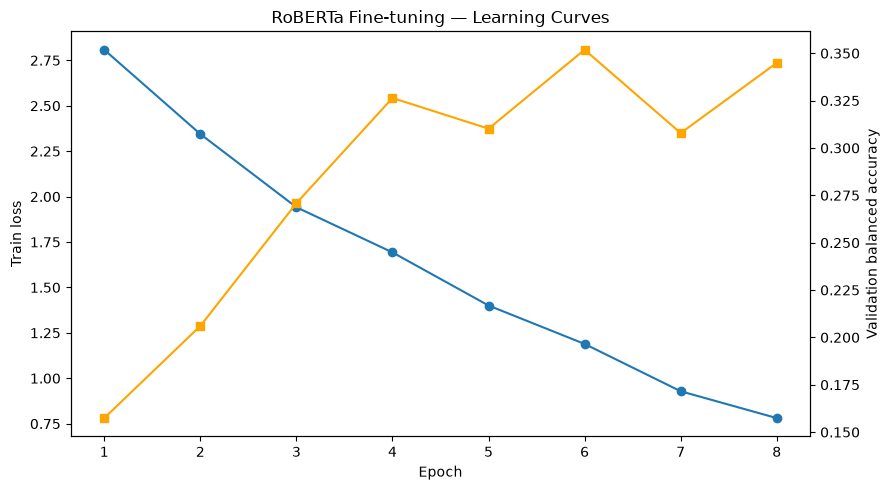

In [10]:
# Diagnostic: first fold only
outer_tr, outer_te = folds[0]

inner_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=SEED,
)

inner_tr, inner_val = next(
    inner_split.split(
        np.zeros(len(outer_tr)),
        y_int[outer_tr],
        groups.iloc[outer_tr],
    )
)

tr = outer_tr[inner_tr]
val = outer_tr[inner_val]

train_loader = DataLoader(
    EncodedTexts(tr),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate,
    num_workers=0,
)

val_loader = DataLoader(
    EncodedTexts(val),
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    collate_fn=collate,
    num_workers=0,
)

torch.manual_seed(SEED)
model = AttributionModel(
    MODEL_ID, len(LABELS)
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY,
)

history = []

for epoch in range(1, 9):
    loss = train_epoch(model, train_loader, optimizer)

    ids, pred = infer(model, val_loader)

    val_score = balanced_accuracy_score(
        y_int[ids], pred
    )

    history.append({
        "epoch": epoch,
        "train_loss": loss,
        "val_balanced_accuracy": val_score,
    })

    print(
        f"Epoch {epoch}/8 | "
        f"loss={loss:.4f} | "
        f"val_bal_acc={val_score:.4f}"
    )

history_df = pd.DataFrame(history)
display(history_df)

best_epoch = int(
    history_df.loc[
        history_df["val_balanced_accuracy"].idxmax(),
        "epoch"
    ]
)

print("Best epoch:", best_epoch)

fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Train loss",
)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Train loss")

ax2 = ax1.twinx()
ax2.plot(
    history_df["epoch"],
    history_df["val_balanced_accuracy"],
    marker="s",
    color="orange",
    label="Validation balanced accuracy",
)
ax2.set_ylabel("Validation balanced accuracy")

plt.title("RoBERTa Fine-tuning — Learning Curves")
plt.tight_layout()
plt.show()


In [12]:
fine_tuned_oof = np.full(len(df), -1, dtype=np.int64)
fold_rows = []
# Embeddings are saved only for each fold's own encoder; they must not be shared across folds.
fold_embeddings = []  # list of (train_idx, eval_idx, emb_train, emb_eval), for optional fusion

for fold, (tr, te) in enumerate(folds, start=1):
    start_time = time.time()
    torch.manual_seed(SEED + fold)
    model = AttributionModel(MODEL_ID, len(LABELS)).to(device)
    train_loader = DataLoader(EncodedTexts(tr), batch_size=BATCH_SIZE,
                              shuffle=True, collate_fn=collate, num_workers=0)
    eval_loader = DataLoader(EncodedTexts(te), batch_size=EVAL_BATCH_SIZE,
                             shuffle=False, collate_fn=collate, num_workers=0)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    for epoch in range(1, EPOCHS + 1):
        train_loss = train_epoch(model, train_loader, optimizer)
        print(f"Fold {fold}/5 · epoch {epoch}/{EPOCHS} · train loss {train_loss:.4f}")

    ids, pred = infer(model, eval_loader)
    fine_tuned_oof[ids] = pred
    bal = balanced_accuracy_score(y_int[te], fine_tuned_oof[te])
    fold_rows.append({"fold":fold, "balanced_accuracy":bal,
                      "accuracy":accuracy_score(y_int[te], fine_tuned_oof[te]),
                      "seconds":round(time.time()-start_time,1)})
    print(f"Fold {fold}: balanced accuracy {bal:.4f}")

    if RUN_FUSION:
        ordered_train_loader = DataLoader(EncodedTexts(tr), batch_size=EVAL_BATCH_SIZE,
                                          shuffle=False, collate_fn=collate, num_workers=0)
        tr_ids, tr_emb = infer(model, ordered_train_loader, get_embeddings=True)
        te_ids, te_emb = infer(model, eval_loader, get_embeddings=True)
        assert np.array_equal(tr_ids, tr) and np.array_equal(te_ids, te)
        fold_embeddings.append((tr.copy(), te.copy(), tr_emb, te_emb))

    del optimizer, model, train_loader, eval_loader
    gc.collect()
    if device.type == "mps": torch.mps.empty_cache()
    elif device.type == "cuda": torch.cuda.empty_cache()

assert (fine_tuned_oof >= 0).all()
ft_fold_scores = pd.DataFrame(fold_rows)
print("Fine-tuned RoBERTa OOF balanced accuracy:",
      round(balanced_accuracy_score(y_int, fine_tuned_oof),4))
display(ft_fold_scores)

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 8006.88it/s]
[transformers] RobertaModel LOAD REPORT from: FacebookAI/roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Fold 1/5 · epoch 1/6 · train loss 2.6778
Fold 1/5 · epoch 2/6 · train loss 2.1717
Fold 1/5 · epoch 3/6 · train loss 1.8567
Fold 1/5 · epoch 4/6 · train loss 1.5875
Fold 1/5 · epoch 5/6 · train loss 1.3540
Fold 1/5 · epoch 6/6 · train loss 1.1398
Fold 1: balanced accuracy 0.3167


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 8518.94it/s]
[transformers] RobertaModel LOAD REPORT from: FacebookAI/roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Fold 2/5 · epoch 1/6 · train loss 2.6529
Fold 2/5 · epoch 2/6 · train loss 2.1681
Fold 2/5 · epoch 3/6 · train loss 1.8214
Fold 2/5 · epoch 4/6 · train loss 1.5978
Fold 2/5 · epoch 5/6 · train loss 1.3423
Fold 2/5 · epoch 6/6 · train loss 1.1561
Fold 2: balanced accuracy 0.3056


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 15245.26it/s]
[transformers] RobertaModel LOAD REPORT from: FacebookAI/roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Fold 3/5 · epoch 1/6 · train loss 2.6924
Fold 3/5 · epoch 2/6 · train loss 2.1081
Fold 3/5 · epoch 3/6 · train loss 1.7703
Fold 3/5 · epoch 4/6 · train loss 1.5220
Fold 3/5 · epoch 5/6 · train loss 1.3074
Fold 3/5 · epoch 6/6 · train loss 1.0779
Fold 3: balanced accuracy 0.3463


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 15741.03it/s]
[transformers] RobertaModel LOAD REPORT from: FacebookAI/roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Fold 4/5 · epoch 1/6 · train loss 2.7242
Fold 4/5 · epoch 2/6 · train loss 2.1243
Fold 4/5 · epoch 3/6 · train loss 1.8355
Fold 4/5 · epoch 4/6 · train loss 1.5612
Fold 4/5 · epoch 5/6 · train loss 1.3004
Fold 4/5 · epoch 6/6 · train loss 1.0920
Fold 4: balanced accuracy 0.3241


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 15601.63it/s]
[transformers] RobertaModel LOAD REPORT from: FacebookAI/roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Fold 5/5 · epoch 1/6 · train loss 2.7610
Fold 5/5 · epoch 2/6 · train loss 2.1257
Fold 5/5 · epoch 3/6 · train loss 1.8069
Fold 5/5 · epoch 4/6 · train loss 1.6127
Fold 5/5 · epoch 5/6 · train loss 1.4148
Fold 5/5 · epoch 6/6 · train loss 1.1575
Fold 5: balanced accuracy 0.3278
Fine-tuned RoBERTa OOF balanced accuracy: 0.3242


,fold,balanced_accuracy,accuracy,seconds
0,1,0.316667,0.316667,491.6
1,2,0.305556,0.305556,496.6
2,3,0.346296,0.346296,495.9
3,4,0.324074,0.324074,497.7
4,5,0.327778,0.328386,497.3


## 4. Optional: fine-tuned embeddings + classical features

For each fold, extract embeddings from **that fold's fine-tuned encoder only**. Train SVM on its training embeddings, then test on its held-out embeddings. Add char TF-IDF and structural stylometry, fitted on training texts only. This tests whether fine-tuned representations complement classical signals.

In [13]:
# Same feature definitions as notebook 05.
START_WORDS = ["beneath", "imagine", "at", "the", "a", "in", "as", "when", "if", "it",
               "you", "we", "there", "this", "but", "and", "for", "on", "with", "while"]
WORD_RE = re.compile(r"[A-Za-z]+(?:['’][A-Za-z]+)?")
SENT_SPLIT_RE = re.compile(r"(?<=[.!?])\s+|\n+")
STYLE_COLS = ["word_count", "sentence_count", "mean_word_len", "std_word_len",
              "mean_sent_len", "std_sent_len", "median_sent_len", "comma_per_100",
              "semicolon_per_100", "colon_per_100", "em_dash_per_100",
              "apostrophe_per_100", "question_per_100"] + [f"start_{w}" for w in START_WORDS] + ["start_other"]

def extract_style(text):
    tokens = [t.lower() for t in WORD_RE.findall(text)]
    lengths = np.array([len(t) for t in tokens], dtype=float)
    segments = [s.strip() for s in SENT_SPLIT_RE.split(text) if WORD_RE.search(s)]
    sentence_tokens = [[t.lower() for t in WORD_RE.findall(s)] for s in segments]
    sent_lengths = np.array([len(s) for s in sentence_tokens], dtype=float)
    starts = Counter(s[0] for s in sentence_tokens if s)
    first_n = sum(starts.values()); per100 = 100/max(1, len(tokens))
    out = {"word_count":float(len(tokens)), "sentence_count":float(len(segments)),
           "mean_word_len":float(lengths.mean()) if len(lengths) else 0.,
           "std_word_len":float(lengths.std()) if len(lengths) else 0.,
           "mean_sent_len":float(sent_lengths.mean()) if len(sent_lengths) else 0.,
           "std_sent_len":float(sent_lengths.std()) if len(sent_lengths) else 0.,
           "median_sent_len":float(np.median(sent_lengths)) if len(sent_lengths) else 0.,
           "comma_per_100":text.count(",")*per100,
           "semicolon_per_100":text.count(";")*per100,
           "colon_per_100":text.count(":")*per100,
           "em_dash_per_100":text.count("—")*per100,
           "apostrophe_per_100":(text.count("'")+text.count("’"))*per100,
           "question_per_100":text.count("?")*per100}
    out.update({f"start_{w}":starts[w]/max(1, first_n) for w in START_WORDS})
    out["start_other"] = (1-sum(out[f"start_{w}"] for w in START_WORDS)) if first_n else 0.
    return out

if RUN_FUSION:
    styles = pd.DataFrame.from_records([extract_style(t) for t in texts], columns=STYLE_COLS)
    fusion_oof = np.empty(len(df),dtype=object)
    fusion_rows = []
    for fold, (tr, te, e_tr, e_te) in enumerate(fold_embeddings, start=1):
        vectorizer = TfidfVectorizer(analyzer="char", ngram_range=(2,5), min_df=2,
                                     sublinear_tf=True, max_features=100_000)
        ch_tr = vectorizer.fit_transform(texts.iloc[tr]); ch_te = vectorizer.transform(texts.iloc[te])
        scaler_style = StandardScaler()
        s_tr = sparse.csr_matrix(normalize(scaler_style.fit_transform(styles.iloc[tr]).astype(np.float32)))
        s_te = sparse.csr_matrix(normalize(scaler_style.transform(styles.iloc[te]).astype(np.float32)))
        scaler_emb = StandardScaler()
        r_tr = sparse.csr_matrix(normalize(scaler_emb.fit_transform(e_tr).astype(np.float32)))
        r_te = sparse.csr_matrix(normalize(scaler_emb.transform(e_te).astype(np.float32)))
        A_tr = sparse.hstack([ch_tr, EMB_WEIGHT*r_tr, STYLE_WEIGHT*s_tr],format="csr")
        A_te = sparse.hstack([ch_te, EMB_WEIGHT*r_te, STYLE_WEIGHT*s_te],format="csr")
        clf = LinearSVC(C=1., max_iter=5000).fit(A_tr, y.iloc[tr])
        preds = clf.predict(A_te)
        fusion_oof[te] = preds
        fusion_rows.append({"fold":fold, "balanced_accuracy":balanced_accuracy_score(y.iloc[te], preds)})
    print("Fine-tuned embeddings + TF-IDF + style OOF:",
          round(balanced_accuracy_score(y, fusion_oof),4))
    display(pd.DataFrame(fusion_rows))
else:
    print("RUN_FUSION=False: skipped fusion")

Fine-tuned embeddings + TF-IDF + style OOF: 0.376


,fold,balanced_accuracy
0,1,0.390741
1,2,0.372222
2,3,0.374074
3,4,0.370370
4,5,0.372478


## 5. Results and Conclusions

Compare all methods on the **same grouped folds**. Note: the `38.23%` result from notebook 05 is a previously selected validation result, not an independent test target.

In [14]:
score_rows = [
    {"approach":"Frozen RoBERTa (notebook 05)", "balanced_accuracy":0.3475},
    {"approach":"Char + style (notebook 05)", "balanced_accuracy":0.3589},
    {"approach":"Frozen fusion (notebook 05)", "balanced_accuracy":0.3823},
    {"approach":"Fine-tuned RoBERTa", "balanced_accuracy":balanced_accuracy_score(y_int, fine_tuned_oof)},
]
if RUN_FUSION:
    score_rows.append({"approach":"Fine-tuned fusion", "balanced_accuracy":balanced_accuracy_score(y, fusion_oof)})
score_table = pd.DataFrame(score_rows).sort_values("balanced_accuracy",ascending=False)
display(score_table.round(4))

fine_tuned_recall = recall_score(y_int, fine_tuned_oof, labels=np.arange(len(LABELS)),
                                 average=None, zero_division=0)
per_model = pd.DataFrame({"model":LABELS, "fine_tuned_recall":fine_tuned_recall})
if RUN_FUSION:
    per_model["fusion_recall"] = recall_score(y, fusion_oof, labels=LABELS,
                                               average=None, zero_division=0)
display(per_model.round(3))

,approach,balanced_accuracy
2,Frozen fusion (notebook 05),0.3823
4,Fine-tuned fusion,0.3760
1,Char + style (notebook 05),0.3589
0,Frozen RoBERTa (notebook 05),0.3475
3,Fine-tuned RoBERTa,0.3242


,model,fine_tuned_recall,fusion_recall
0,claude-fable-5,0.255,0.195
1,claude-opus-4-6,0.633,0.473
2,claude-opus-4-8,0.287,0.327
3,claude-opus-5,0.427,0.513
4,claude-sonnet-5,0.067,0.333
5,gemini-3.1-pro-preview,0.500,0.573
6,gemini-3.6-flash,0.373,0.533
7,gemini-3.7-flash,0.307,0.300
8,gemini-3.8-flash,0.433,0.467
9,glm-5.3,0.200,0.220


## 6. Conclusions

Fine-tuning RoBERTa for six epochs achieved **32.42% balanced accuracy**, while combining fine-tuned embeddings with TF-IDF and stylometric features improved performance to **37.60%**.

However, neither approach surpassed the frozen RoBERTa fusion baseline (**38.23%**).

The learning curves suggest that additional epochs improve performance initially, but the gains become unstable after approximately six epochs.

**Next steps:** Investigate contrastive learning to produce representations that better capture model-specific writing patterns across unseen prompts.